# Detection results: baselines and machine-learning models

This notebook is the reporting layer for the completed detection experiments. It reads the saved Phase 7 baseline results and Phase 8 model results; it does **not** retrain models or create new splits. The tables and figures compare five transparent baselines with the statistical envelope, Isolation Forest, XGBoost and LSTM autoencoder across the four frozen evaluation designs.

The results should be interpreted as an experimental comparison on this dataset, not as evidence of production performance. In particular, the building-held-out design is the closest transfer test, while AHU-held-out and chronological designs answer different generalisation questions.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd()
if not (ROOT / 'configs').exists() and (ROOT.parent / 'configs').exists():
    ROOT = ROOT.parent
BASELINE_DIR = ROOT / 'results' / 'baselines'
DETECTION_DIR = ROOT / 'results' / 'detection'
SPLIT_DIR = ROOT / 'data' / 'interim' / 'evaluation_splits'

def require_artifacts(*paths):
    missing = [str(path) for path in paths if not path.exists()]
    if missing:
        raise FileNotFoundError(
            'Run the baseline and detection commands before executing this notebook.\n'
            + '\n'.join(f'- {path}' for path in missing)
        )

require_artifacts(
    BASELINE_DIR / 'baseline_manifest.json',
    BASELINE_DIR / 'baseline_metrics_by_fold.csv',
    BASELINE_DIR / 'baseline_metrics_summary.csv',
    DETECTION_DIR / 'detection_manifest.json',
    DETECTION_DIR / 'detection_metrics_by_fold.csv',
    DETECTION_DIR / 'detection_metrics_summary.csv',
    SPLIT_DIR / 'evaluation_splits.csv',
)

plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
DESIGN_ORDER = ['ahu_held_out', 'chronological', 'building_held_out', 'nested_grouped']
DESIGN_LABELS = {
    'ahu_held_out': 'AHU held-out',
    'chronological': 'Chronological',
    'building_held_out': 'Building held-out',
    'nested_grouped': 'Nested grouped',
}
MODEL_LABELS = {
    'statistical_envelope': 'Statistical envelope',
    'isolation_forest': 'Isolation Forest',
    'xgboost': 'XGBoost',
    'lstm_autoencoder': 'LSTM autoencoder',
}


In [2]:
with (BASELINE_DIR / 'baseline_manifest.json').open() as handle:
    baseline_manifest = json.load(handle)
with (DETECTION_DIR / 'detection_manifest.json').open() as handle:
    detection_manifest = json.load(handle)

splits = pd.read_csv(SPLIT_DIR / 'evaluation_splits.csv')
baseline_folds = pd.read_csv(BASELINE_DIR / 'baseline_metrics_by_fold.csv')
baseline_summary = pd.read_csv(BASELINE_DIR / 'baseline_metrics_summary.csv')
detection_folds = pd.read_csv(DETECTION_DIR / 'detection_metrics_by_fold.csv')
detection_summary = pd.read_csv(DETECTION_DIR / 'detection_metrics_summary.csv')

print(f'Rows in frozen split assignments across all designs: {len(splits):,}')
print(f'Baseline methods: {len(baseline_manifest["baseline_names"])}')
print(f'Detection models requested: {", ".join(detection_manifest["models_requested"])}')
display(
    splits.groupby(['design', 'fold', 'split'], sort=False)
    .size().rename('rows').reset_index()
    .pivot_table(index=['design', 'fold'], columns='split', values='rows', fill_value=0)
    .reindex(DESIGN_ORDER, level=0)
)

Rows in frozen split assignments across all designs: 3,549,550
Baseline methods: 5
Detection models requested: statistical_envelope, isolation_forest, xgboost, lstm_autoencoder


split                           test     train  validation
design            fold                                    
ahu_held_out      fold_001   77788.0  199399.0     77768.0
chronological     fold_001   71015.0  212946.0     70994.0
building_held_out fold_001  113375.0  175532.0     66048.0
                  fold_002   66048.0  175532.0    113375.0
                  fold_003  175532.0   66048.0    113375.0
nested_grouped    fold_001   77322.0  217459.0     60174.0
                  fold_002   69066.0  225554.0     60335.0
                  fold_003   69523.0  225152.0     60280.0
                  fold_004   69522.0  225211.0     60222.0
                  fold_005   69522.0  225675.0     59758.0

## Evaluation coverage

All methods use the same saved split assignments. The metrics below are means across the folds in each design; the fold-level tables remain available for checking variability. The main binary target is `Normal condition` versus `fault`, so F1, recall and false-positive rate should be read together rather than treating accuracy alone as sufficient.

In [3]:
BASELINE_DISPLAY = {
    'baseline': 'method',
    'mean_accuracy': 'accuracy',
    'mean_balanced_accuracy': 'balanced_accuracy',
    'mean_precision': 'precision',
    'mean_recall': 'recall',
    'mean_f1': 'f1',
    'mean_false_positive_rate': 'false_positive_rate',
}
baseline_table = baseline_summary.rename(columns=BASELINE_DISPLAY).copy()
baseline_table['design'] = baseline_table['design'].map(DESIGN_LABELS)
baseline_table['method'] = baseline_table['method'].str.replace('_', ' ').str.title()
display(
    baseline_table[['design', 'method', 'folds', 'rows', 'accuracy', 'balanced_accuracy', 'precision', 'recall', 'f1', 'false_positive_rate']]
    .sort_values(['design', 'f1'], ascending=[True, False])
    .style.format({column: '{:.3f}' for column in ['accuracy', 'balanced_accuracy', 'precision', 'recall', 'f1', 'false_positive_rate']})
)

,design,method,folds,rows,accuracy,balanced_accuracy,precision,recall,f1,false_positive_rate
0,AHU held-out,Actuator Pump Only,1,77788,0.733,0.619,0.759,0.283,0.413,0.045
3,AHU held-out,Normal Envelope Rule,1,77788,0.709,0.603,0.632,0.289,0.397,0.083
4,AHU held-out,Temperature Only,1,77788,0.725,0.608,0.741,0.261,0.386,0.045
2,AHU held-out,Missingness Only,1,77788,0.685,0.582,0.548,0.275,0.367,0.112
1,AHU held-out,Majority Class,1,77788,0.669,0.500,0.000,0.000,0.000,0.000
8,Building held-out,Normal Envelope Rule,3,354955,0.607,0.581,0.414,0.509,0.430,0.347
9,Building held-out,Temperature Only,3,354955,0.649,0.533,0.399,0.195,0.255,0.128
5,Building held-out,Actuator Pump Only,3,354955,0.676,0.502,0.180,0.016,0.029,0.012
6,Building held-out,Majority Class,3,354955,0.675,0.500,0.000,0.000,0.000,0.000
7,Building held-out,Missingness Only,3,354955,0.675,0.500,0.000,0.000,0.000,0.000


In [4]:
detection_table = detection_summary.copy()
detection_table['design'] = detection_table['design'].map(DESIGN_LABELS)
detection_table['variant'] = detection_table['variant'].str.replace('_', ' ').str.title()
detection_table['model'] = detection_table['model'].map(MODEL_LABELS)
detection_columns = ['design', 'variant', 'model', 'folds', 'scored_rows', 'mean_f1', 'mean_macro_f1', 'mean_balanced_accuracy', 'mean_precision', 'mean_recall', 'mean_false_positive_rate']
display(
    detection_table[detection_columns]
    .sort_values(['design', 'mean_f1'], ascending=[True, False])
    .style.format({column: '{:.3f}' for column in ['mean_f1', 'mean_macro_f1', 'mean_balanced_accuracy', 'mean_precision', 'mean_recall', 'mean_false_positive_rate']})
)

,design,variant,model,folds,scored_rows,mean_f1,mean_macro_f1,mean_balanced_accuracy,mean_precision,mean_recall,mean_false_positive_rate
1,AHU held-out,Operational Context,XGBoost,1,77788,0.965,0.974,0.968,0.991,0.940,0.004
5,AHU held-out,Physical Signal,XGBoost,1,77788,0.963,0.973,0.968,0.984,0.943,0.008
4,AHU held-out,Physical Signal,Statistical envelope,1,77788,0.397,0.603,0.603,0.632,0.289,0.083
2,AHU held-out,Physical Signal,Isolation Forest,1,77788,0.132,0.471,0.532,0.835,0.072,0.007
0,AHU held-out,Operational Context,Isolation Forest,1,77788,0.073,0.438,0.514,0.656,0.039,0.010
3,AHU held-out,Physical Signal,LSTM autoencoder,1,77689,0.030,0.416,0.504,0.517,0.016,0.007
10,Building held-out,Physical Signal,Statistical envelope,3,354955,0.430,0.553,0.581,0.414,0.509,0.347
7,Building held-out,Operational Context,XGBoost,3,354955,0.378,0.583,0.614,0.758,0.352,0.124
11,Building held-out,Physical Signal,XGBoost,3,354955,0.372,0.577,0.599,0.725,0.322,0.123
6,Building held-out,Operational Context,Isolation Forest,3,354955,0.264,0.528,0.572,0.566,0.237,0.093


## Baseline comparison

These five baselines establish progressively stronger reference points: a no-skill majority prediction, a transparent normal-envelope rule, missingness-only evidence, temperature-only evidence, and actuator/pump-only evidence. They are important because a machine-learning model is only useful if it improves on simple, explainable alternatives under the same split.

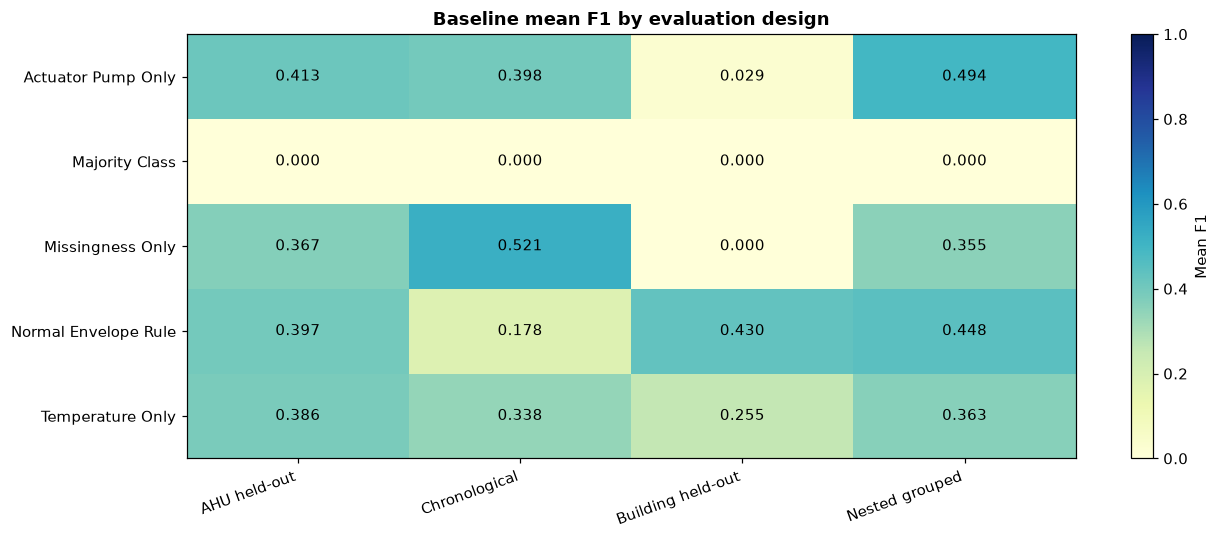

In [5]:
baseline_f1 = baseline_summary.pivot(index='baseline', columns='design', values='mean_f1').reindex(columns=DESIGN_ORDER)
baseline_f1.index = baseline_f1.index.str.replace('_', ' ').str.title()
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(baseline_f1.to_numpy(), cmap='YlGnBu', vmin=0, vmax=1, aspect='auto')
ax.set_title('Baseline mean F1 by evaluation design')
ax.set_xticks(range(len(DESIGN_ORDER)), [DESIGN_LABELS[d] for d in DESIGN_ORDER], rotation=20, ha='right')
ax.set_yticks(range(len(baseline_f1.index)), baseline_f1.index)
for row in range(baseline_f1.shape[0]):
    for col in range(baseline_f1.shape[1]):
        value = baseline_f1.iloc[row, col]
        ax.text(col, row, f'{value:.3f}', ha='center', va='center', color='white' if value > 0.55 else 'black')
fig.colorbar(im, ax=ax, label='Mean F1')
plt.tight_layout()
plt.show()

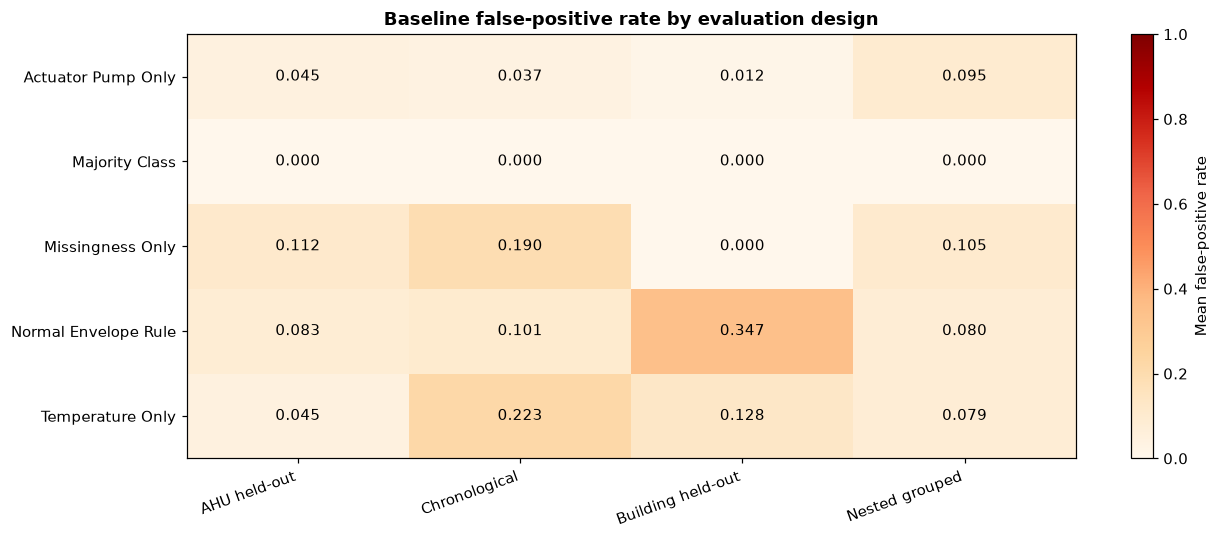

In [6]:
baseline_fpr = baseline_summary.pivot(index='baseline', columns='design', values='mean_false_positive_rate').reindex(columns=DESIGN_ORDER)
baseline_fpr.index = baseline_fpr.index.str.replace('_', ' ').str.title()
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(baseline_fpr.to_numpy(), cmap='OrRd', vmin=0, vmax=1, aspect='auto')
ax.set_title('Baseline false-positive rate by evaluation design')
ax.set_xticks(range(len(DESIGN_ORDER)), [DESIGN_LABELS[d] for d in DESIGN_ORDER], rotation=20, ha='right')
ax.set_yticks(range(len(baseline_fpr.index)), baseline_fpr.index)
for row in range(baseline_fpr.shape[0]):
    for col in range(baseline_fpr.shape[1]):
        value = baseline_fpr.iloc[row, col]
        ax.text(col, row, f'{value:.3f}', ha='center', va='center', color='white' if value > 0.55 else 'black')
fig.colorbar(im, ax=ax, label='Mean false-positive rate')
plt.tight_layout()
plt.show()

## Model comparison

The next view includes every saved Phase 8 model/feature-variant combination. Blank cells are intentional: the statistical envelope and LSTM autoencoder were defined for the physical-signal variant only. The operational-context variant adds missingness and operating-context information; it is therefore a sensitivity comparison rather than a directly interchangeable physical-signal model.

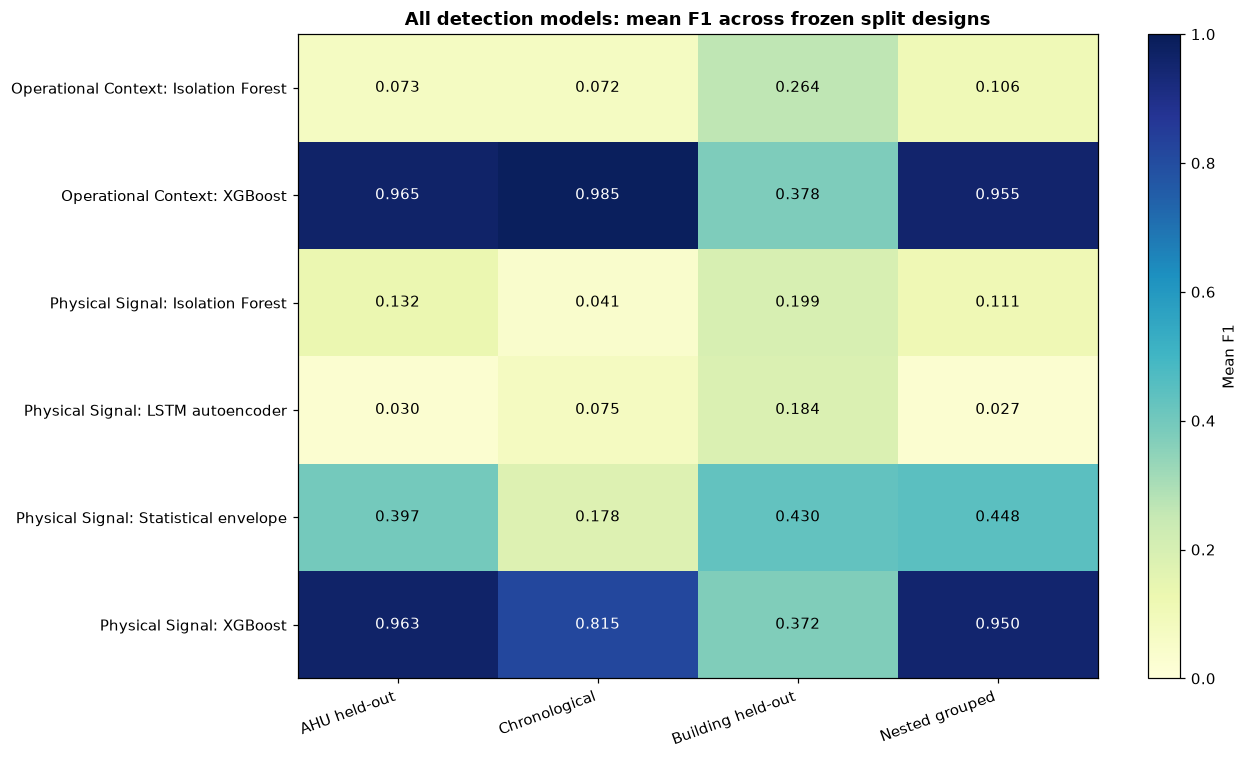

In [7]:
det_plot = detection_summary.copy()
det_plot['method'] = det_plot['variant'].str.replace('_', ' ').str.title() + ': ' + det_plot['model'].map(MODEL_LABELS)
det_f1 = det_plot.pivot(index='method', columns='design', values='mean_f1').reindex(columns=DESIGN_ORDER)
fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(det_f1.to_numpy(), cmap='YlGnBu', vmin=0, vmax=1, aspect='auto')
ax.set_title('All detection models: mean F1 across frozen split designs')
ax.set_xticks(range(len(DESIGN_ORDER)), [DESIGN_LABELS[d] for d in DESIGN_ORDER], rotation=20, ha='right')
ax.set_yticks(range(len(det_f1.index)), det_f1.index)
for row in range(det_f1.shape[0]):
    for col in range(det_f1.shape[1]):
        value = det_f1.iloc[row, col]
        if pd.notna(value):
            ax.text(col, row, f'{value:.3f}', ha='center', va='center', color='white' if value > 0.55 else 'black')
fig.colorbar(im, ax=ax, label='Mean F1')
plt.tight_layout()
plt.show()

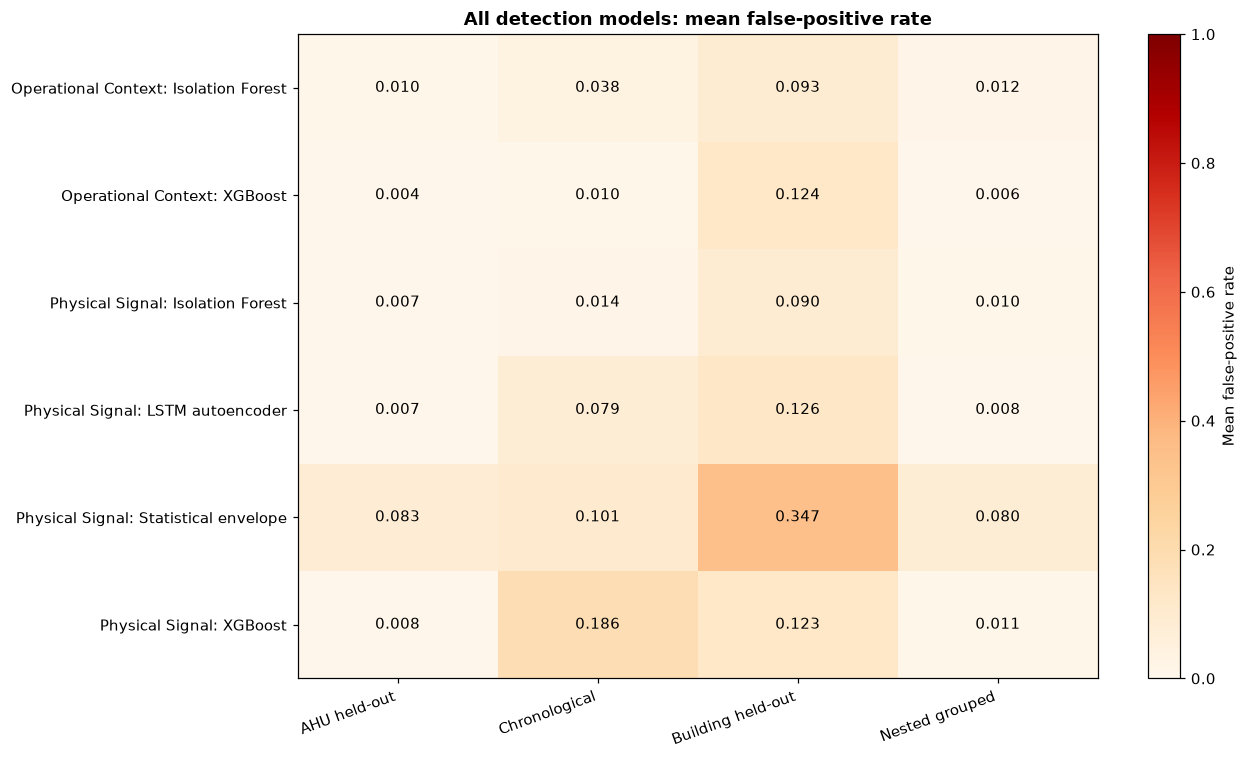

In [8]:
det_fpr = det_plot.pivot(index='method', columns='design', values='mean_false_positive_rate').reindex(columns=DESIGN_ORDER)
fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(det_fpr.to_numpy(), cmap='OrRd', vmin=0, vmax=1, aspect='auto')
ax.set_title('All detection models: mean false-positive rate')
ax.set_xticks(range(len(DESIGN_ORDER)), [DESIGN_LABELS[d] for d in DESIGN_ORDER], rotation=20, ha='right')
ax.set_yticks(range(len(det_fpr.index)), det_fpr.index)
for row in range(det_fpr.shape[0]):
    for col in range(det_fpr.shape[1]):
        value = det_fpr.iloc[row, col]
        if pd.notna(value):
            ax.text(col, row, f'{value:.3f}', ha='center', va='center', color='white' if value > 0.55 else 'black')
fig.colorbar(im, ax=ax, label='Mean false-positive rate')
plt.tight_layout()
plt.show()

## Physical versus operational context

This comparison isolates the effect of the declared feature variants for Isolation Forest and XGBoost. It is not a claim that one variant is universally better: the appropriate choice depends on whether the deployment environment reliably exposes operational context and whether transfer performance is the priority.

mean_f1                  \
variant                            operational_context physical_signal   
design            model                                                  
ahu_held_out      isolation_forest               0.073           0.132   
                  xgboost                        0.965           0.963   
building_held_out isolation_forest               0.264           0.199   
                  xgboost                        0.378           0.372   
chronological     isolation_forest               0.072           0.041   
                  xgboost                        0.985           0.815   
nested_grouped    isolation_forest               0.106           0.111   
                  xgboost                        0.955           0.950   

                                   mean_false_positive_rate                  
variant                                 operational_context physical_signal  
design            model                                                      
ahu_held_out      isolation_forest                    0.010           0.007  
                  xgboost                             0.004           0.008  
building_held_out isolation_forest                    0.093           0.090  
                  xgboost                             0.124           0.123  
chronological     isolation_forest                    0.038           0.014  
                  xgboost                             0.010           0.186  
nested_grouped    isolation_forest                    0.012           0.010  
                  xgboost                             0.006           0.011

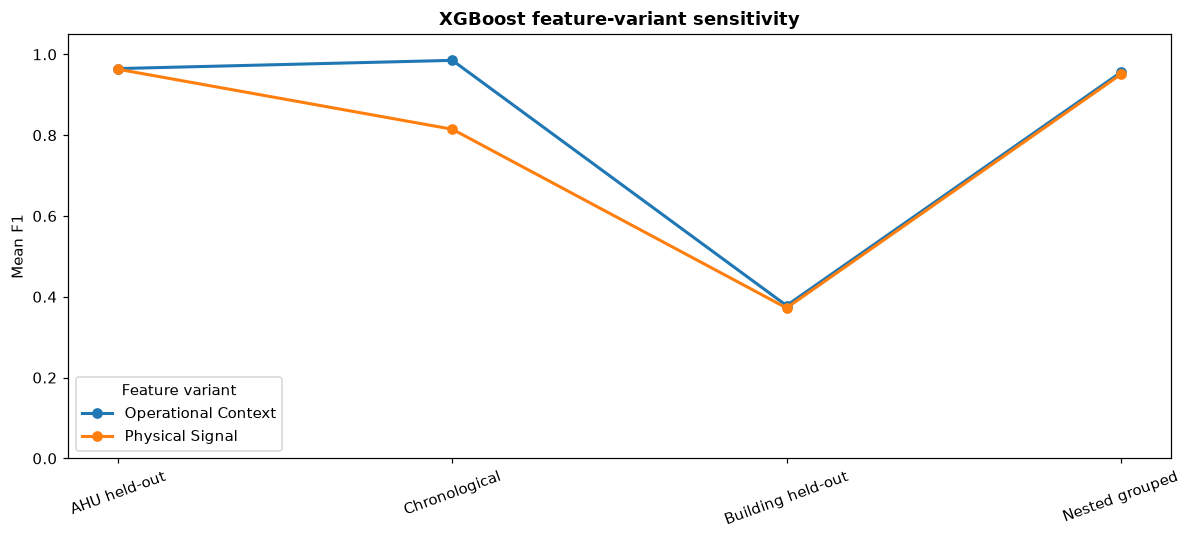

In [9]:
variant_table = (
    detection_summary[detection_summary['model'].isin(['xgboost', 'isolation_forest'])]
    .pivot_table(index=['design', 'model'], columns='variant', values=['mean_f1', 'mean_false_positive_rate'])
)
display(variant_table.round(3))

xgb = detection_summary[detection_summary['model'] == 'xgboost'].copy()
fig, ax = plt.subplots(figsize=(11, 5))
for variant, group in xgb.groupby('variant'):
    values = group.set_index('design').reindex(DESIGN_ORDER)['mean_f1']
    ax.plot([DESIGN_LABELS[d] for d in DESIGN_ORDER], values, marker='o', linewidth=2, label=variant.replace('_', ' ').title())
ax.set_title('XGBoost feature-variant sensitivity')
ax.set_ylabel('Mean F1')
ax.set_ylim(0, 1.05)
ax.legend(title='Feature variant')
ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

## Scoring coverage and LSTM sequence warm-up

The model runner reports `scored_rows` and `unscored_rows`. The LSTM leaves the first `sequence_length - 1` test rows of each AHU unscored because a complete history window is not available; these rows are not silently treated as normal or faulty. The plot checks that coverage explicitly.

,design,method,rows,scored_rows,unscored_rows,scored_rate
0,ahu_held_out,Operational Context: Isolation Forest,77788,77788,0,1.0
1,ahu_held_out,Operational Context: XGBoost,77788,77788,0,1.0
2,ahu_held_out,Physical Signal: Isolation Forest,77788,77788,0,1.0
3,ahu_held_out,Physical Signal: LSTM autoencoder,77689,77689,99,1.0
4,ahu_held_out,Physical Signal: Statistical envelope,77788,77788,0,1.0
5,ahu_held_out,Physical Signal: XGBoost,77788,77788,0,1.0
6,building_held_out,Operational Context: Isolation Forest,354955,354955,0,1.0
7,building_held_out,Operational Context: XGBoost,354955,354955,0,1.0
8,building_held_out,Physical Signal: Isolation Forest,354955,354955,0,1.0
9,building_held_out,Physical Signal: LSTM autoencoder,354504,354504,451,1.0


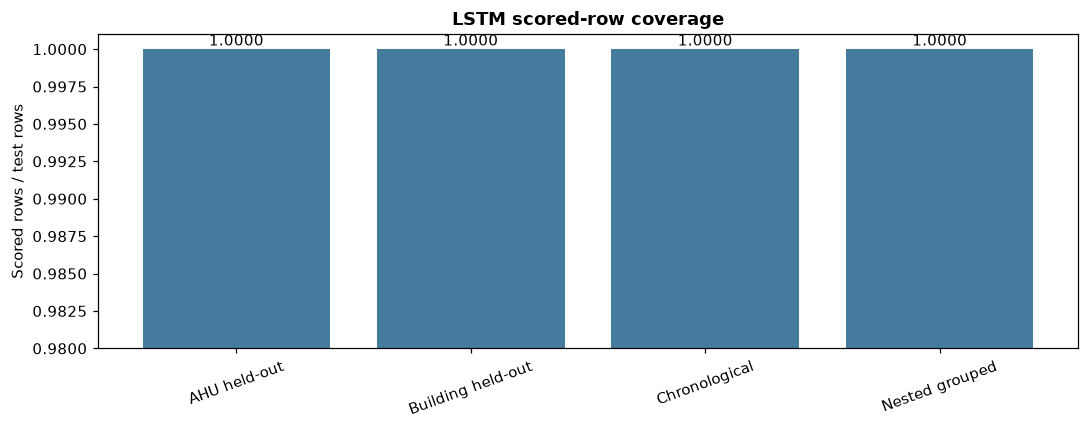

In [10]:
coverage = (
    detection_folds.groupby(['design', 'variant', 'model'], as_index=False)[['rows', 'scored_rows', 'unscored_rows']]
    .sum()
)
coverage['scored_rate'] = coverage['scored_rows'] / coverage['rows']
coverage['method'] = coverage['variant'].str.replace('_', ' ').str.title() + ': ' + coverage['model'].map(MODEL_LABELS)
display(coverage[['design', 'method', 'rows', 'scored_rows', 'unscored_rows', 'scored_rate']].sort_values(['design', 'scored_rate']))

lstm_coverage = coverage[coverage['model'] == 'lstm_autoencoder'].copy()
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar([DESIGN_LABELS[d] for d in lstm_coverage['design']], lstm_coverage['scored_rate'], color='#457b9d')
ax.set_title('LSTM scored-row coverage')
ax.set_ylabel('Scored rows / test rows')
ax.set_ylim(0.98, 1.001)
ax.tick_params(axis='x', rotation=20)
for bar, value in zip(bars, lstm_coverage['scored_rate']):
    ax.text(bar.get_x() + bar.get_width() / 2, value, f'{value:.4f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()

## Evidence-led reading of the results

* XGBoost is the strongest detector in the within-dataset AHU-held-out, chronological and nested-grouped comparisons, with mean F1 above 0.95 in the physical-signal variant for AHU-held-out and nested-grouped evaluation.
* The building-held-out design is substantially harder: the best machine-learning result is much lower, and the transparent normal-envelope baseline is competitive. This is the most important warning against claiming that the within-dataset result automatically transfers to a new building.
* Isolation Forest and the LSTM autoencoder are useful comparative experiments, but their lower F1 shows that an unsupervised or sequence-reconstruction approach is not automatically better than a labelled tree model on this dataset.
* False-positive rate changes the operational interpretation. A high F1 with a materially higher false-positive rate can create an alert burden, so the selected model should be justified using both detection quality and transfer behaviour.
* Operational context improves some XGBoost split results, but it is a declared sensitivity comparison. The physical-signal result remains important because it tests whether measured sensor behaviour alone is sufficient.

In [11]:
best_xgb = (
    detection_summary[detection_summary['model'] == 'xgboost']
    .sort_values(['design', 'mean_f1'], ascending=[True, False])
    .groupby('design', as_index=False).first()
    [['design', 'variant', 'mean_f1', 'mean_precision', 'mean_recall', 'mean_false_positive_rate']]
)
best_baseline = (
    baseline_summary.sort_values(['design', 'mean_f1'], ascending=[True, False])
    .groupby('design', as_index=False).first()
    [['design', 'baseline', 'mean_f1', 'mean_precision', 'mean_recall', 'mean_false_positive_rate']]
)
display(Markdown('### Best XGBoost variant by split design'))
display(best_xgb.assign(design=best_xgb['design'].map(DESIGN_LABELS)).round(3))
display(Markdown('### Best transparent baseline by split design'))
display(best_baseline.assign(design=best_baseline['design'].map(DESIGN_LABELS)).round(3))

print('Fold-level audit:')
print(f'  Baseline fold rows: {len(baseline_folds):,}')
print(f'  Detection fold rows: {len(detection_folds):,}')
print(f'  Detection summary rows: {len(detection_summary):,}')
print(f'  Total unscored detection rows: {int(detection_folds["unscored_rows"].sum()):,}')

### Best XGBoost variant by split design

,design,variant,mean_f1,mean_precision,mean_recall,mean_false_positive_rate
0,AHU held-out,operational_context,0.965,0.991,0.940,0.004
1,Building held-out,operational_context,0.378,0.758,0.352,0.124
2,Chronological,operational_context,0.985,0.977,0.994,0.010
3,Nested grouped,operational_context,0.955,0.987,0.934,0.006


### Best transparent baseline by split design

,design,baseline,mean_f1,mean_precision,mean_recall,mean_false_positive_rate
0,AHU held-out,actuator_pump_only,0.413,0.759,0.283,0.045
1,Building held-out,normal_envelope_rule,0.430,0.414,0.509,0.347
2,Chronological,missingness_only,0.521,0.530,0.512,0.190
3,Nested grouped,actuator_pump_only,0.494,0.677,0.393,0.095


Fold-level audit:
  Baseline fold rows: 50
  Detection fold rows: 60
  Detection summary rows: 24
  Total unscored detection rows: 1,452


## Reproducibility note

The generated CSV files and manifests are intentionally ignored by Git because they are derived artefacts. On a fresh checkout, run the audit/ingestion/split commands followed by the baseline and detection commands in `README.md`, then execute this notebook. The notebook itself is presentation code; the tested package modules remain the source of truth.